11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10 | G Loss: 0.8707 | D Loss: 0.5636


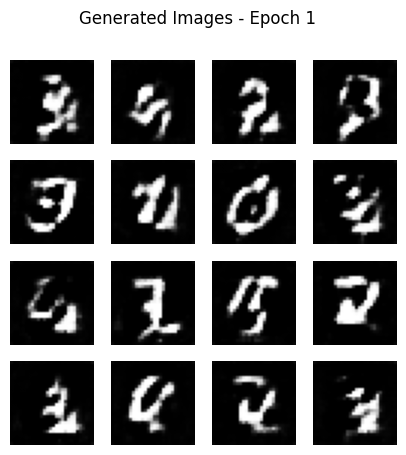

Epoch 2/10 | G Loss: 0.8412 | D Loss: 0.6313


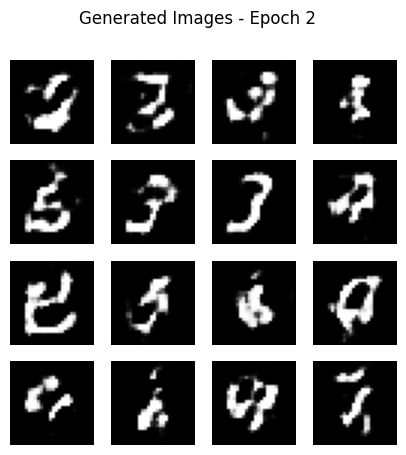

Epoch 3/10 | G Loss: 0.9114 | D Loss: 0.5944


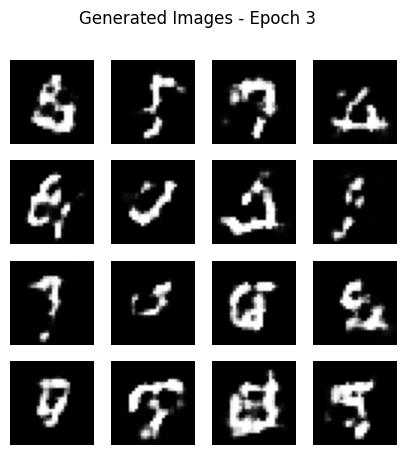

Epoch 4/10 | G Loss: 0.9768 | D Loss: 0.5745


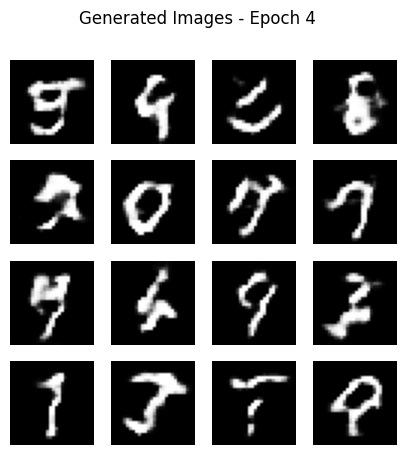

Epoch 5/10 | G Loss: 0.9614 | D Loss: 0.5873


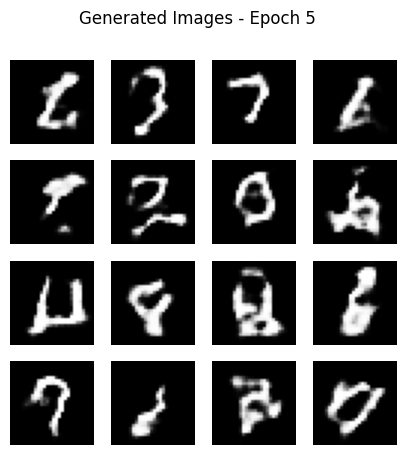

Epoch 6/10 | G Loss: 0.9219 | D Loss: 0.6059


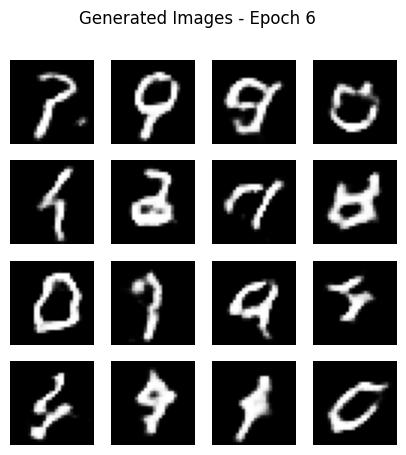

Epoch 7/10 | G Loss: 0.9044 | D Loss: 0.6162


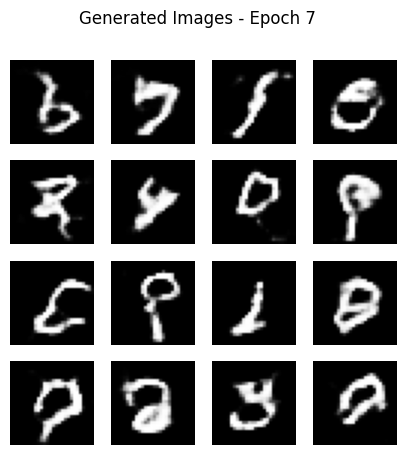

Epoch 8/10 | G Loss: 0.8924 | D Loss: 0.6238


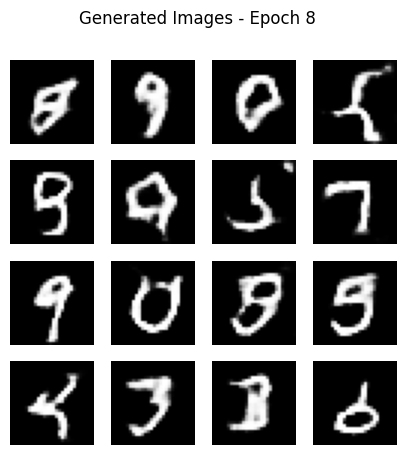

Epoch 9/10 | G Loss: 0.8731 | D Loss: 0.6276


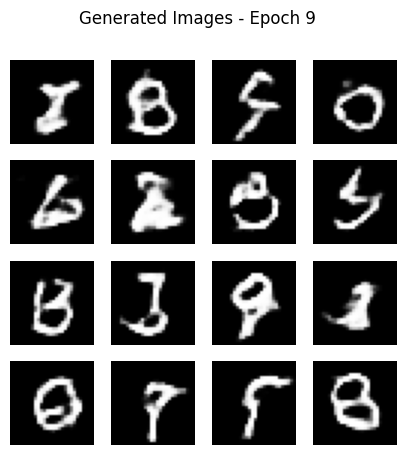

Epoch 10/10 | G Loss: 0.8797 | D Loss: 0.6247


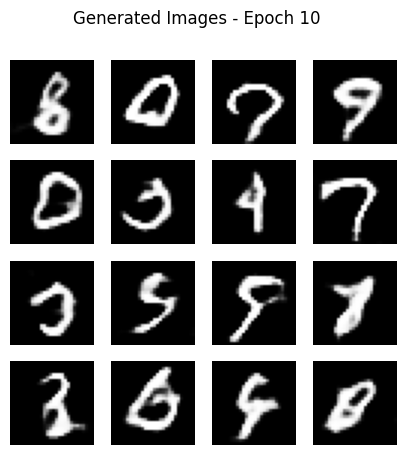

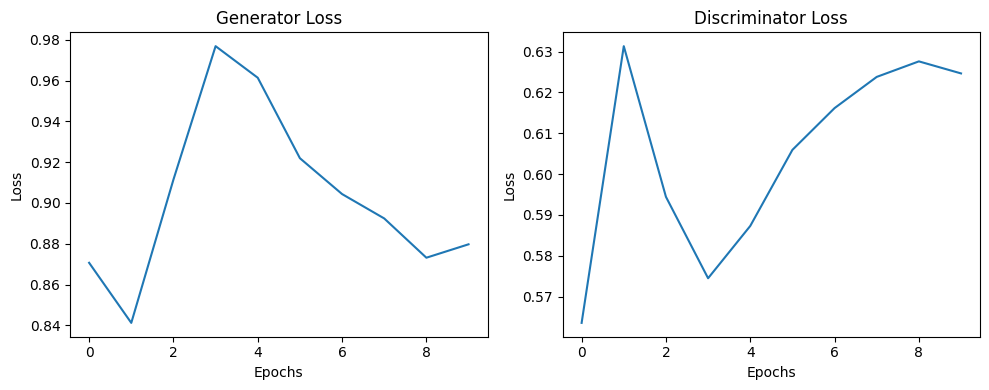

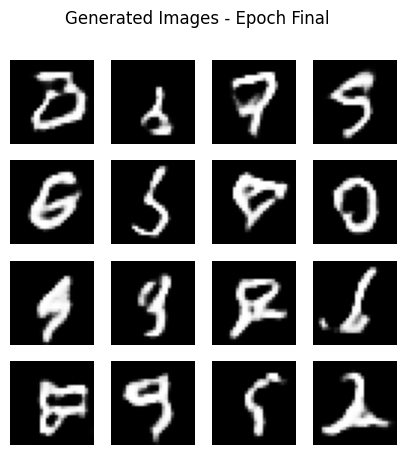

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST
(x, _), (_, _) = tf.keras.datasets.mnist.load_data()
x = (x.astype("float32") - 127.5) / 127.5
x = x.reshape(-1, 28, 28, 1)

dataset = tf.data.Dataset.from_tensor_slices(x).shuffle(60000).batch(128)

# Generator
generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(100,)),
    tf.keras.layers.Dense(7*7*128),
    tf.keras.layers.Reshape((7,7,128)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2DTranspose(64, 4, strides=2, padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh")
])

# Discriminator
discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28,28,1)),
    tf.keras.layers.Conv2D(64, 4, strides=2, padding="same"),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Conv2D(128, 4, strides=2, padding="same"),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1)
])

# Loss and optimizers
loss_fn = tf.keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)
d_opt = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)

# Training
def train_step(real):
    noise = tf.random.normal([tf.shape(real)[0], 100])

    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake = generator(noise, training=True)
        real_out = discriminator(real, training=True)
        fake_out = discriminator(fake, training=True)

        g_loss = loss_fn(tf.ones_like(fake_out), fake_out)
        d_loss = (loss_fn(tf.ones_like(real_out), real_out) +
                  loss_fn(tf.zeros_like(fake_out), fake_out)) / 2

    gg = gt.gradient(g_loss, generator.trainable_variables)
    dg = dt.gradient(d_loss, discriminator.trainable_variables)

    g_opt.apply_gradients(zip(gg, generator.trainable_variables))
    d_opt.apply_gradients(zip(dg, discriminator.trainable_variables))

    return g_loss, d_loss

# Generate images
def show_images(epoch):
    noise = tf.random.normal([16, 100])
    images = generator(noise, training=False)
    plt.figure(figsize=(5,5))
    for i in range(16):
        plt.subplot(4,4,i+1)
        plt.imshow(images[i,:,:,0]*0.5+0.5, cmap="gray")
        plt.axis("off")
    plt.suptitle(f"Generated Images - Epoch {epoch}")
    plt.savefig(f"generated_{epoch}.png")
    plt.show()

# Train GAN
gl, dl = [], []

for epoch in range(10):
    g_losses, d_losses = [], []

    for batch in dataset:
        g, d = train_step(batch)
        g_losses.append(g.numpy())
        d_losses.append(d.numpy())

    gl.append(np.mean(g_losses))
    dl.append(np.mean(d_losses))

    print(f"Epoch {epoch+1}/10 | G Loss: {gl[-1]:.4f} | D Loss: {dl[-1]:.4f}")
    show_images(epoch+1)

# Loss graphs
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(gl)
plt.title("Generator Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.subplot(1,2,2)
plt.plot(dl)
plt.title("Discriminator Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()

# Final generated images
show_images("Final")